<a href="https://colab.research.google.com/github/FattahulAlim/244107020018-mobile-course/blob/main/JS09/TG9_2_244107020018_MFattahulAlim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

path_dataset = '/content/drive/MyDrive/ml-sem5/JS09/dataset/spam.csv'
df = pd.read_csv(path_dataset, encoding='latin-1')

df = df.iloc[:, :2]                 # ambil 2 kolom pertama saja
df.columns = ['Labels', 'SMS']      # rename column
df['Labels'] = df['Labels'].map({'spam': 1, 'ham': 0})
df.head()

Mounted at /content/drive


,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
from sklearn.model_selection import train_test_split

X = df['SMS'].values
y = df['Labels'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

In [ ]:
# Soal 1 Fitur CountVectorizer dengan mengaktifkan stop_words
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

bow = CountVectorizer(stop_words='english')
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

mnb_bow = MultinomialNB()
mnb_bow.fit(X_train_bow, y_train)

pred_train = mnb_bow.predict(X_train_bow)
pred_bow = mnb_bow.predict(X_test_bow)

print('Akurasi train:', accuracy_score(y_train, pred_train))
print('Akurasi test :', accuracy_score(y_test, pred_bow))
print(confusion_matrix(y_test, pred_bow))
print(classification_report(y_test, pred_bow, target_names=['ham', 'spam']))

Akurasi train: 0.9946152120260264
Akurasi test : 0.9829596412556054
[[951   3]
 [ 16 145]]
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [ ]:
# Soal 2 Fitur TF-IDF dengan mengaktifkan stop_words
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train)

pred_train = mnb_tfidf.predict(X_train_tfidf)
pred_tfidf = mnb_tfidf.predict(X_test_tfidf)

print('Akurasi train:', accuracy_score(y_train, pred_train))
print('Akurasi test :', accuracy_score(y_test, pred_tfidf))
print(confusion_matrix(y_test, pred_tfidf))
print(classification_report(y_test, pred_tfidf, target_names=['ham', 'spam']))

Akurasi train: 0.9842943684092439
Akurasi test : 0.9605381165919282
[[954   0]
 [ 44 117]]
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       954
        spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



                  CountVectorizer  TF-IDF
Accuracy                   0.9830  0.9605
Precision (spam)           0.9797  1.0000
Recall (spam)              0.9006  0.7267
F1 (spam)                  0.9385  0.8417


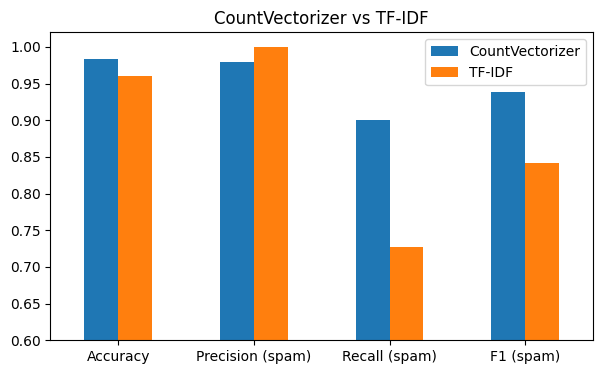

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

hasil = pd.DataFrame({
    'CountVectorizer': [accuracy_score(y_test, pred_bow), precision_score(y_test, pred_bow),
                        recall_score(y_test, pred_bow), f1_score(y_test, pred_bow)],
    'TF-IDF': [accuracy_score(y_test, pred_tfidf), precision_score(y_test, pred_tfidf),
               recall_score(y_test, pred_tfidf), f1_score(y_test, pred_tfidf)]
}, index=['Accuracy', 'Precision (spam)', 'Recall (spam)', 'F1 (spam)'])

print(hasil.round(4))
hasil.plot(kind='bar', figsize=(7, 4))
plt.ylim(0.6, 1.02)
plt.title('CountVectorizer vs TF-IDF')
plt.xticks(rotation=0)
plt.show()

# Kesimpulan

Berdasarkan percobaan klasifikasi pesan SMS menggunakan algoritma Multinomial Naive Bayes pada dataset spam.csv, dilakukan perbandingan dua metode ekstraksi fitur teks, yaitu CountVectorizer dan TF-IDF, dengan mengaktifkan parameter stop_words='english'.

Hasil evaluasi menunjukkan bahwa CountVectorizer memperoleh akurasi training sebesar 99,46% dan akurasi testing sebesar 98,30%. Sementara itu, TF-IDF memperoleh akurasi training sebesar 98,43% dan akurasi testing sebesar 96,05%. Pada klasifikasi kelas spam, CountVectorizer menghasilkan precision sebesar 97,97%, recall sebesar 90,06%, dan F1-score sebesar 93,85%. Adapun TF-IDF menghasilkan precision sebesar 100%, recall sebesar 72,67%, dan F1-score sebesar 84,17%.

Berdasarkan hasil tersebut, CountVectorizer merupakan metode ekstraksi fitur yang lebih baik untuk kasus klasifikasi spam pada percobaan ini, karena menghasilkan akurasi, recall, dan F1-score yang lebih tinggi. Metode ini lebih mampu mengenali pesan spam secara keseluruhan. Sebaliknya, TF-IDF memiliki precision spam yang lebih tinggi, tetapi recall yang lebih rendah menunjukkan bahwa masih terdapat lebih banyak pesan spam yang diklasifikasikan sebagai pesan biasa (ham).

Dengan demikian, CountVectorizer lebih direkomendasikan untuk model pada percobaan ini, terutama apabila tujuan utamanya adalah mendeteksi sebanyak mungkin pesan spam dengan tetap mempertahankan akurasi klasifikasi yang tinggi. Meskipun demikian, hasil ini berlaku berdasarkan dataset, pembagian data, dan konfigurasi model yang digunakan dalam eksperimen.